# Automated Hyperparameter Tuning and Performance Comparison of Neural Networks for Multiclass Sentiment Analysis

**Dataset:** Sp1786/multiclass-sentiment-analysis-dataset  
**Classes:** Negative, Neutral, Positive  
**Platform:** Google Colab  
**Framework:** TensorFlow / Keras  
**Hyperparameter Optimization:** KerasTuner  

### Project Objective

This project aims to implement and compare four neural network architectures: Neural Network (NN), Simple Recurrent Neural Network (RNN), Long Short-Term Memory (LSTM), and Gated Recurrent Unit (GRU) for multiclass sentiment classification. Automated hyperparameter tuning is performed using KerasTuner to identify suitable model configurations and evaluate their classification performance.

### Methodology

- Dataset loading and exploratory data analysis.
- Text preprocessing, tokenization and sequence padding.
- Splitting the dataset into separate training, validation and testing sets.
- Implementation and training of four neural network architectures.
- Automated hyperparameter optimization using KerasTuner.
- Model evaluation using accuracy, precision, recall and Macro F1-score.
- Comparison of baseline and optimized model performance.

### Hyperparameter Optimization

The Neural Network model is optimized using validation Macro F1-score, whereas Simple RNN, LSTM and GRU models are optimized using validation accuracy.

### Expected Outcome

Identify and compare the best-performing neural network architectures based on validation and test performance, and analyze the impact of automated hyperparameter tuning on multiclass sentiment classification.

### 1. Installing Required Libraries
Install the libraries required for dataset handling, deep learning, hyperparameter tuning and model evaluation.

In [4]:
!pip install -q datasets keras-tuner

### 2. Importing Required Libraries
Import the necessary libraries for data processing, neural network development, optimization and visualization.

In [5]:
# Data processing
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Dataset loading
from datasets import load_dataset

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Hyperparameter tuning
import keras_tuner as kt

# Utilities
import random
import os
import time

# Reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print("Libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

Libraries imported successfully!
TensorFlow Version: 2.21.0


### 3. Loading the Dataset
Load the official training, validation and testing datasets from Hugging Face for multiclass sentiment analysis.

In [6]:
# Load the official dataset splits
dataset = load_dataset(
    "csv",
    data_files={
        "train": "https://huggingface.co/datasets/Sp1786/multiclass-sentiment-analysis-dataset/resolve/main/train_df.csv",
        "validation": "https://huggingface.co/datasets/Sp1786/multiclass-sentiment-analysis-dataset/resolve/main/val_df.csv",
        "test": "https://huggingface.co/datasets/Sp1786/multiclass-sentiment-analysis-dataset/resolve/main/test_df.csv"
    }
)

# Convert datasets into Pandas DataFrames
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Dataset loaded successfully!")

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Dataset loaded successfully!


### 4. Exploring the Dataset
Examine the dataset dimensions, columns, data types and sample records across all three splits.

In [7]:
# Display dataset shapes
print("Training Dataset:", train_df.shape)
print("Validation Dataset:", val_df.shape)
print("Testing Dataset:", test_df.shape)

# Display column information
print("\nDataset Columns:")
print(train_df.columns.tolist())

# Display sample records
print("\nTraining Dataset:")
display(train_df.head())

print("\nValidation Dataset:")
display(val_df.head())

print("\nTesting Dataset:")
display(test_df.head())

Training Dataset: (31232, 4)
Validation Dataset: (5205, 4)
Testing Dataset: (5206, 4)

Dataset Columns:
['id', 'text', 'label', 'sentiment']

Training Dataset:


,id,text,label,sentiment
0,9536,"Cooking microwave pizzas, yummy",2,positive
1,6135,Any plans of allowing sub tasks to show up in ...,1,neutral
2,17697,"I love the humor, I just reworded it. Like sa...",2,positive
3,14182,naw idk what ur talkin about,1,neutral
4,17840,That sucks to hear. I hate days like that,0,negative



Validation Dataset:


,id,text,label,sentiment
0,317,Laying in bed til workkk... Oh the life. Defin...,0,negative
1,24292,ooohhh imma need you to get on that asap love...,2,positive
2,3513,"Thanks! I love it they have a video, so you d...",2,positive
3,4322,I left my ipod in the car so now its all warm.,2,positive
4,6203,Great app. Only complaint is that I'd like the...,2,positive



Testing Dataset:


,id,text,label,sentiment
0,9235,getting cds ready for tour,1,neutral
1,16790,"MC, happy mother`s day to your mom ;).. love yah",2,positive
2,24840,A year from now is graduation....i am pretty s...,0,negative
3,20744,because you had chips and sale w/o me,1,neutral
4,6414,Great for organising my work life balance,2,positive


### 5. Sentiment Distribution Analysis
Examine the distribution of negative, neutral and positive sentiment classes to identify potential class imbalance.

Training Sentiment Distribution:
sentiment
neutral     11649
positive    10478
negative     9105
Name: count, dtype: int64


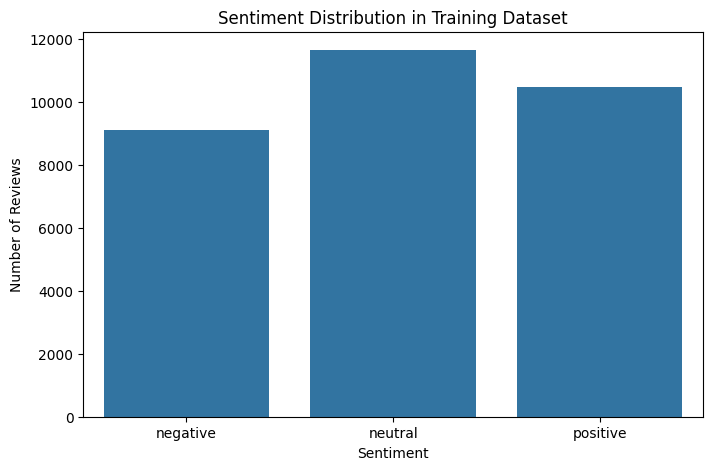

In [8]:
# Display sentiment distribution
print("Training Sentiment Distribution:")
print(train_df["sentiment"].value_counts())

# Visualize sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="sentiment",
    order=["negative", "neutral", "positive"]
)

plt.title("Sentiment Distribution in Training Dataset")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

### 6. Data Quality Assessment
Check for missing values and duplicate records in the training, validation and testing datasets.

In [9]:
# Check missing values
print("Missing Values:")
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name} Dataset:")
    print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"{name}: {df.duplicated().sum()}")

Missing Values:

Training Dataset:
id           0
text         0
label        0
sentiment    0
dtype: int64

Validation Dataset:
id           0
text         0
label        0
sentiment    0
dtype: int64

Testing Dataset:
id           0
text         1
label        0
sentiment    0
dtype: int64

Duplicate Records:
Training: 0
Validation: 0
Testing: 0


### 7. Sentiment Label Encoding
Convert negative, neutral and positive sentiment labels into numerical classes for multiclass classification.

In [10]:
# Define sentiment encoding
label_mapping = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

# Encode sentiment labels
for df in [train_df, val_df, test_df]:
    df["label"] = df["sentiment"].str.lower().map(label_mapping)

# Display encoded labels
print("Label Encoding:")
print(label_mapping)

print("\nTraining Labels:")
print(train_df[["sentiment", "label"]].head())

Label Encoding:
{'negative': 0, 'neutral': 1, 'positive': 2}

Training Labels:
  sentiment  label
0  positive      2
1   neutral      1
2  positive      2
3   neutral      1
4  negative      0


### 8. Separating Features and Labels
Separate review text as input features and encoded sentiment labels as target variables for all dataset splits.

In [11]:
# Extract text features
X_train_text = train_df["text"].astype(str).tolist()
X_val_text = val_df["text"].astype(str).tolist()
X_test_text = test_df["text"].astype(str).tolist()

# Extract sentiment labels
y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

print("Training Samples:", len(X_train_text))
print("Validation Samples:", len(X_val_text))
print("Testing Samples:", len(X_test_text))

Training Samples: 31232
Validation Samples: 5205
Testing Samples: 5206


### 9. Text Tokenization
Convert text reviews into numerical sequences using a tokenizer fitted exclusively on the training dataset.

In [12]:
# Define vocabulary size
VOCAB_SIZE = 20000

# Initialize tokenizer
tokenizer = keras.preprocessing.text.Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

# Fit tokenizer only on training data
tokenizer.fit_on_texts(X_train_text)

# Convert text into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq = tokenizer.texts_to_sequences(X_val_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

print("Tokenization completed!")
print("Vocabulary Size:", len(tokenizer.word_index))

Tokenization completed!
Vocabulary Size: 29766


### 10. Sequence Length Analysis
Analyze review sequence lengths to determine a suitable padding length for neural network input.

Sequence Length Statistics:
count    31232.000000
mean        18.445184
std         17.876992
min          0.000000
25%          8.000000
50%         14.000000
75%         22.000000
max        393.000000
dtype: float64


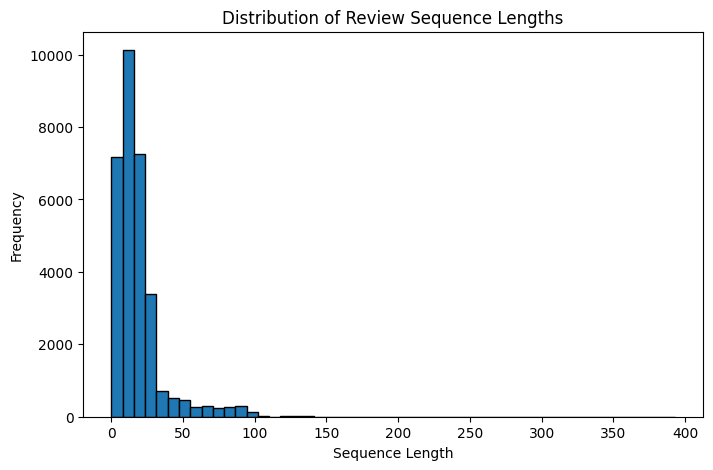

In [13]:
# Calculate sequence lengths
sequence_lengths = [len(seq) for seq in X_train_seq]

# Display statistics
print("Sequence Length Statistics:")
print(pd.Series(sequence_lengths).describe())

# Visualize sequence lengths
plt.figure(figsize=(8, 5))
plt.hist(sequence_lengths, bins=50, edgecolor="black")

plt.title("Distribution of Review Sequence Lengths")
plt.xlabel("Sequence Length")
plt.ylabel("Frequency")
plt.show()

### 11. Sequence Padding
Apply padding to convert variable-length text sequences into fixed-length arrays suitable for neural network training.

In [14]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("pad_sequences imported successfully!")

pad_sequences imported successfully!


In [15]:
# Define maximum sequence length
MAX_LEN = 200

# Apply padding
X_train = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

# Display final shapes
print("Final Preprocessed Data Shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Final Preprocessed Data Shapes:
Training: (31232, 200)
Validation: (5205, 200)
Testing: (5206, 200)


### 12. Baseline Neural Network Implementation
Build a feedforward neural network using an Embedding layer, Global Average Pooling and Dense layers for multiclass sentiment classification.

In [16]:
# Define baseline neural network
def build_nn_model():

    model = keras.Sequential([
        layers.Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=64
        ),

        layers.GlobalAveragePooling1D(),

        layers.Dense(64, activation="relu"),

        layers.Dropout(0.3),

        layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Build model
nn_model = build_nn_model()

# Display model architecture
nn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### 13. Training the Baseline Neural Network
Train the baseline neural network using training data and monitor its performance on the validation dataset.

In [17]:
# Define early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Record training start time
start_time = time.time()

# Train the model
nn_history = nn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

# Calculate training time
nn_training_time = time.time() - start_time

print(f"\nTraining Time: {nn_training_time:.2f} seconds")

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.3710 - loss: 1.0944 - val_accuracy: 0.3704 - val_loss: 1.0928
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3736 - loss: 1.0923 - val_accuracy: 0.3735 - val_loss: 1.0872
Epoch 3/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4058 - loss: 1.0739 - val_accuracy: 0.4559 - val_loss: 1.0684
Epoch 4/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5178 - loss: 0.9555 - val_accuracy: 0.4692 - val_loss: 1.0417
Epoch 5/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5817 - loss: 0.8720 - val_accuracy: 0.5979 - val_loss: 0.8874
Epoch 6/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6205 - loss: 0.8256 - val_accuracy: 0.5456 - val_loss: 0.9570
Epoch 7/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6420 - loss: 0.7927 - val_accuracy: 0.6396 - val_loss: 0.7952
Epoch 8/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6575 - loss: 0.7684 - val_accuracy: 0

### 14. Baseline Model Performance Visualization
Visualize training and validation accuracy and loss to understand the learning performance of the baseline neural network.

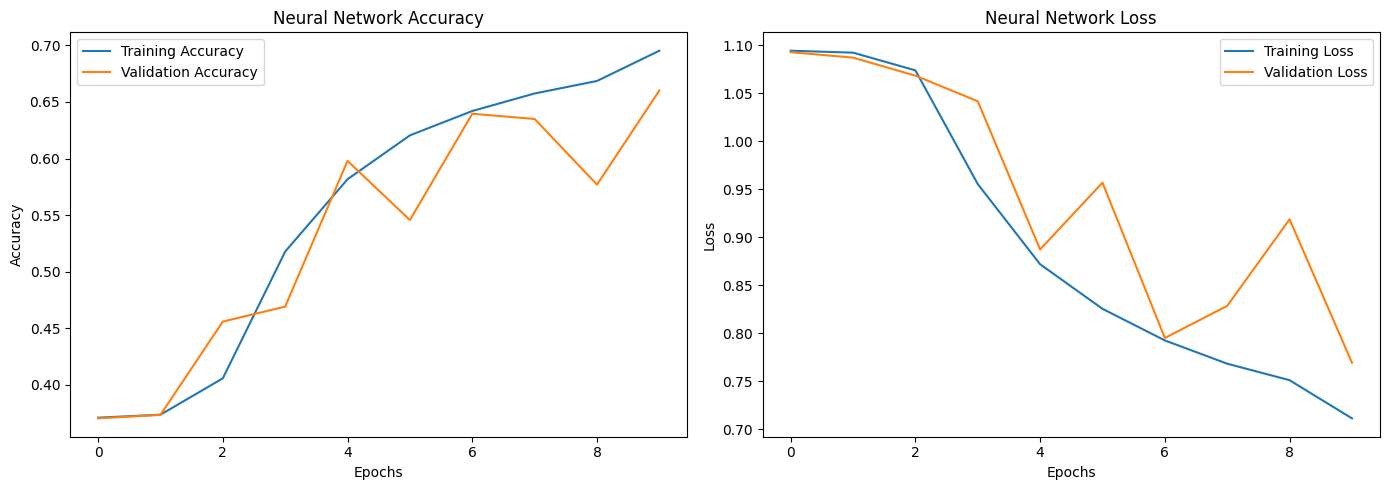

In [18]:
# Plot accuracy and loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(nn_history.history["accuracy"], label="Training Accuracy")
axes[0].plot(nn_history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Neural Network Accuracy")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss
axes[1].plot(nn_history.history["loss"], label="Training Loss")
axes[1].plot(nn_history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Neural Network Loss")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

### 15. Baseline Neural Network Evaluation
Evaluate the baseline neural network on validation data using accuracy, precision, recall and macro-F1 score.

In [19]:
# Generate validation predictions
nn_val_prob = nn_model.predict(X_val)
nn_val_pred = np.argmax(nn_val_prob, axis=1)

# Calculate evaluation metrics
nn_val_results = {
    "Model": "Neural Network",
    "Accuracy": accuracy_score(y_val, nn_val_pred),
    "Precision": precision_score(y_val, nn_val_pred, average="macro", zero_division=0),
    "Recall": recall_score(y_val, nn_val_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_val, nn_val_pred, average="macro", zero_division=0)
}

# Display results
print("Baseline Neural Network - Validation Results")
display(pd.DataFrame([nn_val_results]))

163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Baseline Neural Network - Validation Results


,Model,Accuracy,Precision,Recall,Macro F1
0,Neural Network,0.660134,0.702696,0.648524,0.657448


### 16. Neural Network Hyperparameter Tuning
Define the search space for embedding dimensions, dense units, dropout and learning rate to automatically identify the optimal neural network configuration.

In [20]:
# Define the neural network model with tunable hyperparameters
def build_tuned_nn(hp):

    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),

        layers.Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=hp.Choice(
                "embedding_dim",
                [32, 64, 128]
            )
        ),

        layers.GlobalAveragePooling1D(),

        layers.Dense(
            units=hp.Choice("dense_units", [32, 64, 128]),
            activation="relu"
        ),

        layers.Dropout(
            rate=hp.Choice("dropout", [0.2, 0.3, 0.5])
        ),

        layers.Dense(3, activation="softmax")
    ])

    # Tune learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        [0.001, 0.0005, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

### 17. Validation Macro-F1 Monitoring
Calculate validation macro-F1 after each epoch to use balanced classification performance as the hyperparameter optimization objective.

In [21]:
from sklearn.metrics import f1_score

class MacroF1Callback(keras.callbacks.Callback):

    def __init__(self, validation_data):
        super().__init__()
        self.X_val, self.y_val = validation_data

    def on_epoch_end(self, epoch, logs=None):

        predictions = self.model.predict(
            self.X_val, verbose=0
        )

        predicted_classes = np.argmax(predictions, axis=1)

        macro_f1 = f1_score(
            self.y_val,
            predicted_classes,
            average="macro"
        )

        logs["val_macro_f1"] = macro_f1

        print(f" - val_macro_f1: {macro_f1:.4f}")

### 18. Configuring Automated Hyperparameter Search
Configure Random Search to explore different neural network configurations and select the best model based on validation macro-F1.

In [27]:
# Configure hyperparameter tuner
nn_tuner = kt.RandomSearch(
    hypermodel=build_tuned_nn,
    objective=kt.Objective(
        "val_macro_f1",
        direction="max"
    ),
    max_trials=10,
    executions_per_trial=1,
    directory="nn_tuning",
    project_name="nn_10_trials",
    overwrite=True,
    seed=SEED
)

# Display search space
nn_tuner.search_space_summary()

Search space summary
Default search space size: 4
embedding_dim (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128], 'ordered': True}
dense_units (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128], 'ordered': True}
dropout (Choice)
{'default': 0.2, 'conditions': [], 'values': [0.2, 0.3, 0.5], 'ordered': True}
learning_rate (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.001, 0.0005, 0.0001], 'ordered': True}


### 19. Executing Neural Network Hyperparameter Optimization
Train multiple neural network configurations and evaluate their validation macro-F1 scores to identify the best hyperparameters.

In [28]:
# Define callbacks
nn_tuning_callbacks = [
    MacroF1Callback((X_val, y_val)),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

# Start hyperparameter search
start_time = time.time()

nn_tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=nn_tuning_callbacks,
    verbose=1
)

nn_tuning_time = time.time() - start_time

print(f"\nTotal Tuning Time: {nn_tuning_time:.2f} seconds")

Trial 10 Complete [00h 00m 36s]
val_macro_f1: 0.6232199907084532

Best val_macro_f1 So Far: 0.6546133038530438
Total elapsed time: 00h 05m 10s

Total Tuning Time: 310.36 seconds


### 20. Selecting Optimal Neural Network Hyperparameters
Retrieve and display the best hyperparameter combination identified through automated validation macro-F1 optimization.

In [30]:
# Retrieve best hyperparameters
best_nn_hp = nn_tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best Neural Network Hyperparameters:")
for parameter, value in best_nn_hp.values.items():
    print(f"{parameter}: {value}")

Best Neural Network Hyperparameters:
embedding_dim: 64
dense_units: 32
dropout: 0.3
learning_rate: 0.001


### 21. Training the Optimized Neural Network
Build and train the neural network using the optimal hyperparameters identified by KerasTuner.

In [31]:
# Build best neural network
best_nn_model = nn_tuner.hypermodel.build(best_nn_hp)

# Train optimized model
best_nn_history = best_nn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.3722 - loss: 1.0946 - val_accuracy: 0.3704 - val_loss: 1.0933
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3720 - loss: 1.0939 - val_accuracy: 0.3704 - val_loss: 1.0937
Epoch 3/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3734 - loss: 1.0929 - val_accuracy: 0.3704 - val_loss: 1.0911
Epoch 4/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3944 - loss: 1.0806 - val_accuracy: 0.3889 - val_loss: 1.0673
Epoch 5/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5002 - loss: 0.9801 - val_accuracy: 0.4515 - val_loss: 1.0318
Epoch 6/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5737 - loss: 0.8854 - val_accuracy: 0.5606 - val_loss: 0.9172
Epoch 7/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6144 - loss: 0.8332 - val_accuracy: 0.5760 - val_loss: 0.9010
Epoch 8/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6360 - loss: 0.8065 - val_accuracy: 0.

### 22. Evaluating the Optimized Neural Network
Evaluate the optimized neural network on validation data and compare its performance with the baseline model.

In [32]:
# Generate validation predictions
nn_tuned_prob = best_nn_model.predict(X_val)
nn_tuned_pred = np.argmax(nn_tuned_prob, axis=1)

# Calculate evaluation metrics
nn_tuned_results = {
    "Model": "Optimized Neural Network",
    "Accuracy": accuracy_score(y_val, nn_tuned_pred),
    "Precision": precision_score(
        y_val, nn_tuned_pred,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_val, nn_tuned_pred,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, nn_tuned_pred,
        average="macro", zero_division=0
    )
}

# Compare baseline and optimized models
nn_comparison = pd.DataFrame([
    nn_val_results,
    nn_tuned_results
])

display(nn_comparison)

163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


,Model,Accuracy,Precision,Recall,Macro F1
0,Neural Network,0.660134,0.702696,0.648524,0.657448
1,Optimized Neural Network,0.658790,0.687096,0.656247,0.664085


### 23. Simple RNN Model Implementation

A Simple Recurrent Neural Network (RNN) is implemented for multiclass sentiment classification. The model learns sequential patterns in text to predict sentiment categories.

In [33]:
# Build Simple RNN model
def build_rnn_model():
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=64,
            mask_zero=True
        ),
        layers.SimpleRNN(64),
        layers.Dropout(0.3),
        layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

rnn_model = build_rnn_model()
rnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,288,451 (4.92 MB)

 Trainable params: 1,288,451 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

### 24. Training the Baseline Simple RNN

The baseline RNN model is trained using the training dataset and evaluated on the validation dataset. Early stopping is used to prevent unnecessary training.

In [34]:
# Train baseline RNN
rnn_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[rnn_early_stopping],
    verbose=1
)

rnn_training_time = time.time() - start_time

print("RNN Training Time:", round(rnn_training_time, 2), "seconds")

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.5616 - loss: 0.9082 - val_accuracy: 0.6526 - val_loss: 0.7855
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.7424 - loss: 0.6431 - val_accuracy: 0.6451 - val_loss: 0.8324
Epoch 3/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.8415 - loss: 0.4291 - val_accuracy: 0.5988 - val_loss: 1.0133
Epoch 4/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9129 - loss: 0.2526 - val_accuracy: 0.5988 - val_loss: 1.2597
RNN Training Time: 43.21 seconds


### 25. Visualizing RNN Training Performance

The training and validation accuracy and loss are visualized to understand the learning performance of the baseline RNN model.

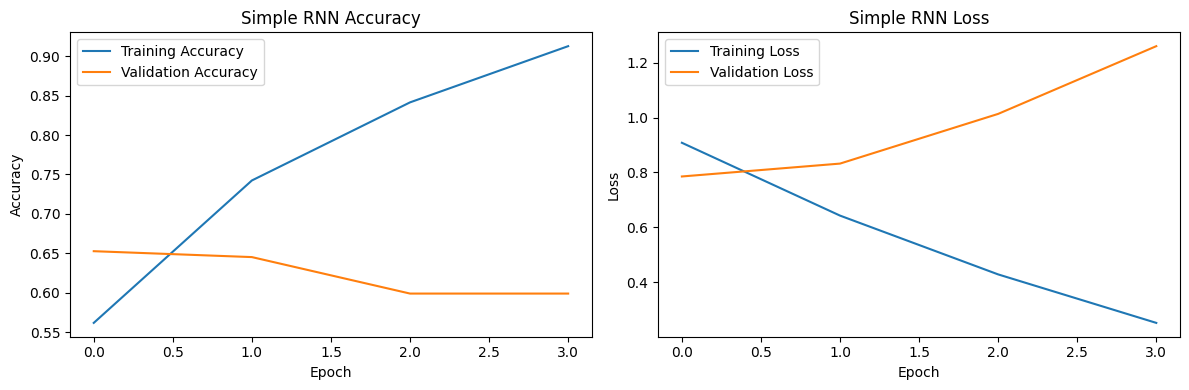

In [35]:
# Plot RNN training performance
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(rnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(rnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Simple RNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(rnn_history.history["loss"], label="Training Loss")
plt.plot(rnn_history.history["val_loss"], label="Validation Loss")
plt.title("Simple RNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

### 26. Baseline RNN Evaluation

The baseline RNN model is evaluated using accuracy, precision, recall, and macro F1-score on the validation dataset.

In [36]:
# Evaluate baseline RNN
rnn_val_prob = rnn_model.predict(X_val)
rnn_val_pred = np.argmax(rnn_val_prob, axis=1)

rnn_val_results = {
    "Model": "Simple RNN",
    "Accuracy": accuracy_score(y_val, rnn_val_pred),
    "Precision": precision_score(y_val, rnn_val_pred, average="macro", zero_division=0),
    "Recall": recall_score(y_val, rnn_val_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_val, rnn_val_pred, average="macro", zero_division=0)
}

display(pd.DataFrame([rnn_val_results]))

163/163 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step


,Model,Accuracy,Precision,Recall,Macro F1
0,Simple RNN,0.652642,0.665462,0.651856,0.656724


### 27. RNN Hyperparameter Tuning

Keras Tuner is used to identify the optimal hyperparameters for the Simple RNN model. The search explores different embedding dimensions, RNN units, dropout rates, and learning rates.

In [37]:
# Define the RNN model for hyperparameter tuning
def build_tuned_rnn(hp):
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),

        layers.Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=hp.Choice("embedding_dim", [32, 64, 128]),
            mask_zero=True
        ),

        layers.SimpleRNN(
            units=hp.Choice("rnn_units", [32, 64, 128])
        ),

        layers.Dropout(
            rate=hp.Choice("dropout", [0.2, 0.3, 0.5])
        ),

        layers.Dense(3, activation="softmax")
    ])

    learning_rate = hp.Choice(
        "learning_rate", [0.001, 0.0005, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

### 28. Configuring RNN Hyperparameter Search

Random Search is configured to explore different combinations of RNN hyperparameters. Validation accuracy is used as the optimization objective to identify the best-performing configuration.

In [38]:
# Configure RNN hyperparameter tuner
rnn_tuner = kt.RandomSearch(
    build_tuned_rnn,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="rnn_tuning",
    project_name="rnn_10_trials",
    overwrite=True,
    seed=SEED
)

print("RNN Hyperparameter Tuner Configured Successfully")

RNN Hyperparameter Tuner Configured Successfully


### 29. Executing RNN Hyperparameter Optimization

Random Search is performed to evaluate different hyperparameter combinations. Each trial trains an RNN model and evaluates its performance on the validation dataset.

In [40]:
# Execute RNN hyperparameter search
start_time = time.time()

rnn_tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=64,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

rnn_tuning_time = time.time() - start_time

print("RNN Tuning Time:", round(rnn_tuning_time, 2), "seconds")

RNN Tuning Time: 0.0 seconds


### 30. Retrieving the Best RNN Hyperparameters

The best hyperparameter combination identified by Random Search is retrieved for building the optimized Simple RNN model.

In [41]:
# Retrieve best RNN hyperparameters
best_rnn_hp = rnn_tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best RNN Hyperparameters:")
print("Embedding Dimension:", best_rnn_hp.get("embedding_dim"))
print("RNN Units:", best_rnn_hp.get("rnn_units"))
print("Dropout:", best_rnn_hp.get("dropout"))
print("Learning Rate:", best_rnn_hp.get("learning_rate"))

Best RNN Hyperparameters:
Embedding Dimension: 64
RNN Units: 32
Dropout: 0.2
Learning Rate: 0.0005


### 31. Training the Optimized Simple RNN

The Simple RNN model is rebuilt using the best hyperparameters identified by Keras Tuner and trained on the training dataset. Early stopping is used to prevent overfitting.

In [42]:
# Build optimized RNN model
optimized_rnn_model = rnn_tuner.hypermodel.build(best_rnn_hp)

optimized_rnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,283,203 (4.90 MB)

 Trainable params: 1,283,203 (4.90 MB)

 Non-trainable params: 0 (0.00 B)

In [43]:
# Train optimized RNN
optimized_rnn_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

optimized_rnn_history = optimized_rnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[optimized_rnn_early_stopping],
    verbose=1
)

optimized_rnn_training_time = time.time() - start_time

print(
    "Optimized RNN Training Time:",
    round(optimized_rnn_training_time, 2),
    "seconds"
)

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.4999 - loss: 0.9917 - val_accuracy: 0.6292 - val_loss: 0.8389
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.7149 - loss: 0.7028 - val_accuracy: 0.6563 - val_loss: 0.7955
Epoch 3/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.8238 - loss: 0.4850 - val_accuracy: 0.6446 - val_loss: 0.8822
Epoch 4/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.8993 - loss: 0.3050 - val_accuracy: 0.6086 - val_loss: 1.0681
Epoch 5/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9380 - loss: 0.1958 - val_accuracy: 0.5940 - val_loss: 1.2371
Optimized RNN Training Time: 57.53 seconds


### 32. Optimized RNN Evaluation

The optimized Simple RNN model is evaluated using accuracy, precision, recall, and macro F1-score on the validation dataset.

In [44]:
# Evaluate optimized RNN
optimized_rnn_val_prob = optimized_rnn_model.predict(X_val)
optimized_rnn_val_pred = np.argmax(optimized_rnn_val_prob, axis=1)

optimized_rnn_results = {
    "Model": "Optimized Simple RNN",
    "Accuracy": accuracy_score(y_val, optimized_rnn_val_pred),
    "Precision": precision_score(
        y_val, optimized_rnn_val_pred,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_val, optimized_rnn_val_pred,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, optimized_rnn_val_pred,
        average="macro", zero_division=0
    )
}

display(pd.DataFrame([optimized_rnn_results]))

163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


,Model,Accuracy,Precision,Recall,Macro F1
0,Optimized Simple RNN,0.656292,0.673626,0.65107,0.657486


### 33. Baseline and Optimized RNN Comparison

The baseline and optimized Simple RNN models are compared using validation accuracy, precision, recall, and macro F1-score to identify the better-performing configuration.

In [45]:
# Compare baseline and optimized RNN
rnn_comparison = pd.DataFrame([
    rnn_val_results,
    optimized_rnn_results
])

display(rnn_comparison)

,Model,Accuracy,Precision,Recall,Macro F1
0,Simple RNN,0.652642,0.665462,0.651856,0.656724
1,Optimized Simple RNN,0.656292,0.673626,0.651070,0.657486


### 34. LSTM Model Implementation

A Long Short-Term Memory (LSTM) network is implemented for multiclass sentiment classification. LSTM networks use memory cells and gates to capture long-term dependencies in sequential text data.

In [46]:
# Build baseline LSTM model
def build_lstm_model():
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=64,
            mask_zero=True
        ),
        layers.LSTM(64, use_cudnn=False),
        layers.Dropout(0.3),
        layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

lstm_model = build_lstm_model()
lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,219 (5.01 MB)

 Trainable params: 1,313,219 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

### 35. Training the Baseline LSTM

The baseline LSTM model is trained using the training dataset and evaluated on the validation dataset. Early stopping is used to prevent overfitting.

In [47]:
# Train baseline LSTM
lstm_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[lstm_early_stopping],
    verbose=1
)

lstm_training_time = time.time() - start_time

print("LSTM Training Time:", round(lstm_training_time, 2), "seconds")

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.6127 - loss: 0.8537 - val_accuracy: 0.6736 - val_loss: 0.7561
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.7398 - loss: 0.6443 - val_accuracy: 0.6724 - val_loss: 0.7701
Epoch 3/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.7989 - loss: 0.5274 - val_accuracy: 0.6596 - val_loss: 0.8345
Epoch 4/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.8322 - loss: 0.4414 - val_accuracy: 0.6561 - val_loss: 0.9221
LSTM Training Time: 47.22 seconds


### 36. Visualization of LSTM Training Performance

The training and validation accuracy and loss are plotted to examine the model's learning behaviour and identify potential overfitting.

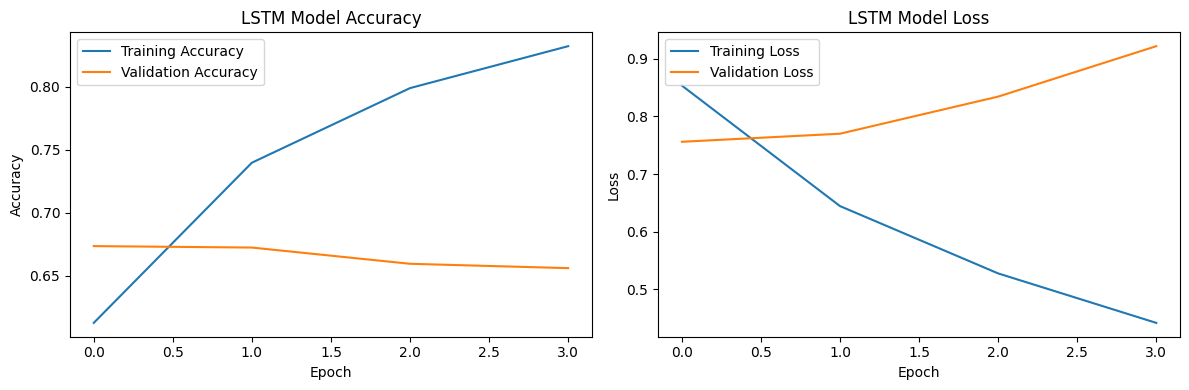

In [48]:
# Plot LSTM training performance
plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(lstm_history.history['accuracy'], label='Training Accuracy')
plt.plot(lstm_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(lstm_history.history['loss'], label='Training Loss')
plt.plot(lstm_history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### 37. Evaluation of Baseline LSTM Model

The baseline LSTM model is evaluated using validation data. Accuracy, macro precision, macro recall, and macro F1-score are calculated to assess its multiclass sentiment classification performance.

In [49]:
# Generate predictions
lstm_val_pred = np.argmax(
    lstm_model.predict(X_val),
    axis=1
)

# Calculate evaluation metrics
lstm_accuracy = accuracy_score(y_val, lstm_val_pred)
lstm_precision = precision_score(y_val, lstm_val_pred, average='macro')
lstm_recall = recall_score(y_val, lstm_val_pred, average='macro')
lstm_f1 = f1_score(y_val, lstm_val_pred, average='macro')

print("Baseline LSTM Model - Validation Results")
print("----------------------------------------")
print(f"Accuracy:  {lstm_accuracy:.4f}")
print(f"Precision: {lstm_precision:.4f}")
print(f"Recall:    {lstm_recall:.4f}")
print(f"Macro F1:  {lstm_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    lstm_val_pred,
    target_names=['Negative', 'Neutral', 'Positive']
))

163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
Baseline LSTM Model - Validation Results
----------------------------------------
Accuracy:  0.6736
Precision: 0.6946
Recall:    0.6681
Macro F1:  0.6753

Classification Report:
              precision    recall  f1-score   support

    Negative       0.74      0.58      0.65      1517
     Neutral       0.57      0.71      0.63      1928
    Positive       0.77      0.72      0.74      1760

    accuracy                           0.67      5205
   macro avg       0.69      0.67      0.68      5205
weighted avg       0.69      0.67      0.68      5205



### 38. LSTM Hyperparameter Tuning

A tunable LSTM architecture is defined using KerasTuner. The embedding dimension, LSTM units, dropout rate, and learning rate are selected from predefined search spaces.

In [53]:
def build_tuned_lstm(hp):
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=hp.Choice("embedding_dim", [32, 64, 128]),
            mask_zero=True
        ),
        layers.LSTM(
            units=hp.Choice("lstm_units", [32, 64, 128]),
            use_cudnn=False
        ),
        layers.Dropout(
            rate=hp.Choice("dropout", [0.2, 0.3, 0.5])
        ),
        layers.Dense(3, activation="softmax")
    ])

    learning_rate = hp.Choice(
        "learning_rate", [0.001, 0.0005, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

### 39. Configuration of LSTM Hyperparameter Tuner

KerasTuner RandomSearch is configured to explore different LSTM hyperparameter combinations. Ten trials are used, with validation accuracy as the optimization objective.

In [54]:
lstm_tuner = kt.RandomSearch(
    build_tuned_lstm,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="lstm_tuning",
    project_name="lstm_10_trials",
    overwrite=True,
    seed=SEED
)

print("LSTM Hyperparameter Tuner Configured Successfully")

LSTM Hyperparameter Tuner Configured Successfully


### 40. Execution of LSTM Hyperparameter Search

The RandomSearch tuner evaluates five different LSTM configurations using the training and validation datasets. Early stopping is applied to reduce unnecessary training and prevent overfitting.

In [55]:
lstm_tuner_start = time.time()

lstm_tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=64,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

lstm_tuning_time = time.time() - lstm_tuner_start

print(f"\nLSTM Hyperparameter Tuning Time: {lstm_tuning_time:.2f} seconds")

Trial 10 Complete [00h 00m 48s]
val_accuracy: 0.6770412921905518

Best val_accuracy So Far: 0.6843419671058655
Total elapsed time: 00h 08m 15s

LSTM Hyperparameter Tuning Time: 494.54 seconds


### 41. Best LSTM Hyperparameter Selection

The best hyperparameter configuration identified by KerasTuner is retrieved for building the optimized LSTM model.

In [56]:
best_lstm_hp = lstm_tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best LSTM Hyperparameters")
print("--------------------------")

for parameter, value in best_lstm_hp.values.items():
    print(f"{parameter}: {value}")

Best LSTM Hyperparameters
--------------------------
embedding_dim: 128
lstm_units: 32
dropout: 0.2
learning_rate: 0.001


### 42. Optimized LSTM Model Implementation

The optimized LSTM model is constructed using the best hyperparameters identified during the tuning process.

In [57]:
optimized_lstm_model = lstm_tuner.hypermodel.build(best_lstm_hp)

optimized_lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,580,707 (9.84 MB)

 Trainable params: 2,580,707 (9.84 MB)

 Non-trainable params: 0 (0.00 B)

### 43. Training of Optimized LSTM Model

The optimized LSTM model is trained using the best hyperparameters obtained from KerasTuner. Early stopping is applied based on validation loss to retain the best-performing model weights.

In [59]:
optimized_lstm_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

optimized_lstm_history = optimized_lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[optimized_lstm_early_stopping],
    verbose=1
)

optimized_lstm_training_time = time.time() - start_time

print(
    f"\nOptimized LSTM Training Time: "
    f"{optimized_lstm_training_time:.2f} seconds"
)

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.7542 - loss: 0.6171 - val_accuracy: 0.6644 - val_loss: 0.7832
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 13s 26ms/step - accuracy: 0.8072 - loss: 0.5041 - val_accuracy: 0.6605 - val_loss: 0.8472
Epoch 3/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.8449 - loss: 0.4181 - val_accuracy: 0.6517 - val_loss: 0.9681
Epoch 4/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.8689 - loss: 0.3520 - val_accuracy: 0.6434 - val_loss: 1.0504

Optimized LSTM Training Time: 50.69 seconds


### 44. Evaluation of Optimized LSTM Model

The optimized LSTM model is evaluated using validation data. Accuracy, macro precision, macro recall, and macro F1-score are calculated to assess its classification performance.

In [60]:
# Generate predictions
optimized_lstm_pred = np.argmax(
    optimized_lstm_model.predict(X_val),
    axis=1
)

# Calculate evaluation metrics
optimized_lstm_accuracy = accuracy_score(y_val, optimized_lstm_pred)
optimized_lstm_precision = precision_score(
    y_val, optimized_lstm_pred, average='macro'
)
optimized_lstm_recall = recall_score(
    y_val, optimized_lstm_pred, average='macro'
)
optimized_lstm_f1 = f1_score(
    y_val, optimized_lstm_pred, average='macro'
)

print("Optimized LSTM Model - Validation Results")
print("-----------------------------------------")
print(f"Accuracy:  {optimized_lstm_accuracy:.4f}")
print(f"Precision: {optimized_lstm_precision:.4f}")
print(f"Recall:    {optimized_lstm_recall:.4f}")
print(f"Macro F1:  {optimized_lstm_f1:.4f}")

163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
Optimized LSTM Model - Validation Results
-----------------------------------------
Accuracy:  0.6644
Precision: 0.6840
Recall:    0.6583
Macro F1:  0.6649


### 45. Performance Comparison of Baseline and Optimized LSTM Models

The baseline and optimized LSTM models are compared using accuracy, macro precision, macro recall, and macro F1-score to determine the effect of hyperparameter tuning.

In [61]:
lstm_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "Macro F1"],
    "Baseline LSTM": [
        lstm_accuracy,
        lstm_precision,
        lstm_recall,
        lstm_f1
    ],
    "Optimized LSTM": [
        optimized_lstm_accuracy,
        optimized_lstm_precision,
        optimized_lstm_recall,
        optimized_lstm_f1
    ]
})

print(lstm_comparison.to_string(index=False))

   Metric  Baseline LSTM  Optimized LSTM
 Accuracy       0.673583        0.664361
Precision       0.694563        0.684037
   Recall       0.668051        0.658341
 Macro F1       0.675343        0.664926


### 46. Baseline GRU Model Implementation

A baseline Gated Recurrent Unit (GRU) model is implemented for multiclass sentiment classification. The model uses an embedding layer, a GRU layer, dropout regularization, and a softmax output layer.

In [62]:
def build_gru_model():
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=64,
            mask_zero=True
        ),
        layers.GRU(64, use_cudnn=False),
        layers.Dropout(0.3),
        layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

gru_model = build_gru_model()
gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,305,155 (4.98 MB)

 Trainable params: 1,305,155 (4.98 MB)

 Non-trainable params: 0 (0.00 B)

### 47. Training of Baseline GRU Model

The baseline GRU model is trained using the training dataset. Early stopping is applied based on validation loss to prevent overfitting and retain the best model weights.

In [63]:
gru_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

gru_history = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[gru_early_stopping],
    verbose=1
)

gru_training_time = time.time() - start_time

print(f"\nBaseline GRU Training Time: {gru_training_time:.2f} seconds")

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.6062 - loss: 0.8563 - val_accuracy: 0.6720 - val_loss: 0.7528
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.7399 - loss: 0.6431 - val_accuracy: 0.6717 - val_loss: 0.7710
Epoch 3/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.7963 - loss: 0.5329 - val_accuracy: 0.6549 - val_loss: 0.8354
Epoch 4/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.8349 - loss: 0.4468 - val_accuracy: 0.6450 - val_loss: 0.9136

Baseline GRU Training Time: 52.41 seconds


### 48. Visualization of GRU Training Performance

The training and validation accuracy and loss are plotted to examine the GRU model's learning behaviour and identify potential overfitting.

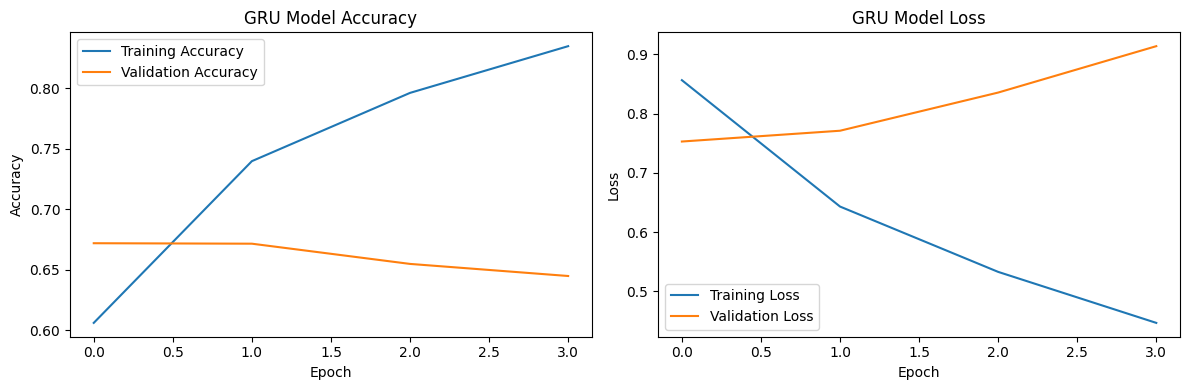

In [64]:
plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(gru_history.history['accuracy'], label='Training Accuracy')
plt.plot(gru_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('GRU Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(gru_history.history['loss'], label='Training Loss')
plt.plot(gru_history.history['val_loss'], label='Validation Loss')
plt.title('GRU Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### 49. Evaluation of Baseline GRU Model

The baseline GRU model is evaluated using validation data. Accuracy, macro precision, macro recall, and macro F1-score are calculated to assess its multiclass sentiment classification performance.

In [65]:
# Generate predictions
gru_val_pred = np.argmax(
    gru_model.predict(X_val),
    axis=1
)

# Calculate evaluation metrics
gru_accuracy = accuracy_score(y_val, gru_val_pred)
gru_precision = precision_score(y_val, gru_val_pred, average='macro')
gru_recall = recall_score(y_val, gru_val_pred, average='macro')
gru_f1 = f1_score(y_val, gru_val_pred, average='macro')

print("Baseline GRU Model - Validation Results")
print("---------------------------------------")
print(f"Accuracy:  {gru_accuracy:.4f}")
print(f"Precision: {gru_precision:.4f}")
print(f"Recall:    {gru_recall:.4f}")
print(f"Macro F1:  {gru_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    gru_val_pred,
    target_names=['Negative', 'Neutral', 'Positive']
))

163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step
Baseline GRU Model - Validation Results
---------------------------------------
Accuracy:  0.6720
Precision: 0.6943
Recall:    0.6657
Macro F1:  0.6728

Classification Report:
              precision    recall  f1-score   support

    Negative       0.75      0.56      0.64      1517
     Neutral       0.57      0.71      0.63      1928
    Positive       0.75      0.73      0.74      1760

    accuracy                           0.67      5205
   macro avg       0.69      0.67      0.67      5205
weighted avg       0.69      0.67      0.67      5205



### 50. GRU Hyperparameter Tuning

A tunable GRU architecture is defined using KerasTuner. The embedding dimension, GRU units, dropout rate, and learning rate are selected from predefined search spaces.

In [66]:
def build_tuned_gru(hp):
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=hp.Choice("embedding_dim", [32, 64, 128]),
            mask_zero=True
        ),
        layers.GRU(
            units=hp.Choice("gru_units", [32, 64, 128]),
            use_cudnn=False
        ),
        layers.Dropout(
            rate=hp.Choice("dropout", [0.2, 0.3, 0.5])
        ),
        layers.Dense(3, activation="softmax")
    ])

    learning_rate = hp.Choice(
        "learning_rate", [0.001, 0.0005, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

### 51. Configuration of GRU Hyperparameter Tuner

KerasTuner RandomSearch is configured to explore different GRU hyperparameter combinations. Ten trials are used, with validation accuracy as the optimization objective.

In [67]:
gru_tuner = kt.RandomSearch(
    build_tuned_gru,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="gru_tuning",
    project_name="gru_10_trials",
    overwrite=True,
    seed=SEED
)

print("GRU Hyperparameter Tuner Configured Successfully")

GRU Hyperparameter Tuner Configured Successfully


### 52. Execution of GRU Hyperparameter Search

The RandomSearch tuner evaluates five different GRU configurations using the training and validation datasets. Early stopping is applied to reduce unnecessary training and prevent overfitting.

In [68]:
gru_tuner_start = time.time()

gru_tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=64,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

gru_tuning_time = time.time() - gru_tuner_start

print(f"\nGRU Hyperparameter Tuning Time: {gru_tuning_time:.2f} seconds")

Trial 10 Complete [00h 00m 51s]
val_accuracy: 0.6666666865348816

Best val_accuracy So Far: 0.6743515729904175
Total elapsed time: 00h 09m 20s

GRU Hyperparameter Tuning Time: 559.61 seconds


### 53. Best GRU Hyperparameter Selection

The best hyperparameter configuration identified by KerasTuner is retrieved for building the optimized GRU model.

In [69]:
best_gru_hp = gru_tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best GRU Hyperparameters")
print("-------------------------")

for parameter, value in best_gru_hp.values.items():
    print(f"{parameter}: {value}")

Best GRU Hyperparameters
-------------------------
embedding_dim: 32
gru_units: 32
dropout: 0.5
learning_rate: 0.0001


### 54. Optimized GRU Model Implementation

The optimized GRU model is constructed using the best hyperparameters identified during the tuning process.

In [70]:
optimized_gru_model = gru_tuner.hypermodel.build(best_gru_hp)

optimized_gru_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 32)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 646,435 (2.47 MB)

 Trainable params: 646,435 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

### 55. Training of Optimized GRU Model

The optimized GRU model is trained using the best hyperparameters obtained from KerasTuner. Early stopping is applied based on validation loss to retain the best-performing model weights.

In [71]:
optimized_gru_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

optimized_gru_history = optimized_gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[optimized_gru_early_stopping],
    verbose=1
)

optimized_gru_training_time = time.time() - start_time

print(
    f"\nOptimized GRU Training Time: "
    f"{optimized_gru_training_time:.2f} seconds"
)

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.3814 - loss: 1.0923 - val_accuracy: 0.3852 - val_loss: 1.0868
Epoch 2/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.4687 - loss: 1.0463 - val_accuracy: 0.5656 - val_loss: 0.9594
Epoch 3/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.6138 - loss: 0.8873 - val_accuracy: 0.6198 - val_loss: 0.8655
Epoch 4/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.6689 - loss: 0.7904 - val_accuracy: 0.6421 - val_loss: 0.8133
Epoch 5/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.7045 - loss: 0.7269 - val_accuracy: 0.6571 - val_loss: 0.7854
Epoch 6/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.7328 - loss: 0.6734 - val_accuracy: 0.6626 - val_loss: 0.7820
Epoch 7/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.7511 - loss: 0.6318 - val_accuracy: 0.6688 - val_loss: 0.7951
Epoch 8/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.7702 - loss: 0.5982 - 

### 56. Evaluation of Optimized GRU Model

The optimized GRU model is evaluated using validation data. Accuracy, macro precision, macro recall, and macro F1-score are calculated to assess its multiclass sentiment classification performance.

In [72]:
# Generate predictions
optimized_gru_pred = np.argmax(
    optimized_gru_model.predict(X_val),
    axis=1
)

# Calculate evaluation metrics
optimized_gru_accuracy = accuracy_score(y_val, optimized_gru_pred)
optimized_gru_precision = precision_score(
    y_val, optimized_gru_pred, average='macro'
)
optimized_gru_recall = recall_score(
    y_val, optimized_gru_pred, average='macro'
)
optimized_gru_f1 = f1_score(
    y_val, optimized_gru_pred, average='macro'
)

print("Optimized GRU Model - Validation Results")
print("----------------------------------------")
print(f"Accuracy:  {optimized_gru_accuracy:.4f}")
print(f"Precision: {optimized_gru_precision:.4f}")
print(f"Recall:    {optimized_gru_recall:.4f}")
print(f"Macro F1:  {optimized_gru_f1:.4f}")

163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
Optimized GRU Model - Validation Results
----------------------------------------
Accuracy:  0.6626
Precision: 0.6761
Recall:    0.6605
Macro F1:  0.6660


### 57. Performance Comparison of Baseline and Optimized GRU Models

The baseline and optimized GRU models are compared using accuracy, macro precision, macro recall, and macro F1-score to evaluate the impact of hyperparameter tuning.

In [73]:
gru_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "Macro F1"],
    "Baseline GRU": [
        gru_accuracy,
        gru_precision,
        gru_recall,
        gru_f1
    ],
    "Optimized GRU": [
        optimized_gru_accuracy,
        optimized_gru_precision,
        optimized_gru_recall,
        optimized_gru_f1
    ]
})

print(gru_comparison.to_string(index=False))

   Metric  Baseline GRU  Optimized GRU
 Accuracy      0.672046       0.662632
Precision      0.694266       0.676116
   Recall      0.665727       0.660530
 Macro F1      0.672807       0.666027


### 58. Overall Performance Comparison of All Models

The performance of all eight models, including baseline and hyperparameter-optimized versions of Neural Network, Simple RNN, LSTM and GRU, is compared using validation accuracy, macro precision, macro recall and macro F1-score.

In [75]:
# Collect validation results of all eight models
overall_results = pd.DataFrame([
    {
        "Model": "Baseline NN",
        "Accuracy": 0.660134,
        "Precision": 0.702696,
        "Recall": 0.648524,
        "Macro F1": 0.657448
    },
    {
        "Model": "Optimized NN",
        "Accuracy": 0.658790,
        "Precision": 0.687096,
        "Recall": 0.656247,
        "Macro F1": 0.664085
    },
    {
        "Model": "Baseline RNN",
        "Accuracy": 0.652642,
        "Precision": 0.665462,
        "Recall": 0.651856,
        "Macro F1": 0.656724
    },
    {
        "Model": "Optimized RNN",
        "Accuracy": 0.656292,
        "Precision": 0.673626,
        "Recall": 0.651070,
        "Macro F1": 0.657486
    },
    {
        "Model": "Baseline LSTM",
        "Accuracy": 0.673583,
        "Precision": 0.694563,
        "Recall": 0.668051,
        "Macro F1": 0.675343
    },
    {
        "Model": "Optimized LSTM",
        "Accuracy": 0.664361,
        "Precision": 0.684037,
        "Recall": 0.658341,
        "Macro F1": 0.664926
    },
    {
        "Model": "Baseline GRU",
        "Accuracy": 0.672046,
        "Precision": 0.694266,
        "Recall": 0.665727,
        "Macro F1": 0.672807
    },
    {
        "Model": "Optimized GRU",
        "Accuracy": 0.662632,
        "Precision": 0.676116,
        "Recall": 0.660530,
        "Macro F1": 0.666027
    }
])

overall_results = overall_results.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

display(overall_results.round(4))

,Model,Accuracy,Precision,Recall,Macro F1
0,Baseline LSTM,0.6736,0.6946,0.6681,0.6753
1,Baseline GRU,0.6720,0.6943,0.6657,0.6728
2,Optimized LSTM,0.6644,0.6840,0.6583,0.6649
3,Optimized GRU,0.6626,0.6761,0.6605,0.6660
4,Baseline NN,0.6601,0.7027,0.6485,0.6574
5,Optimized NN,0.6588,0.6871,0.6562,0.6641
6,Optimized RNN,0.6563,0.6736,0.6511,0.6575
7,Baseline RNN,0.6526,0.6655,0.6519,0.6567


### 59. Visualization of Overall Model Performance

A bar chart is used to compare the validation accuracy and macro F1-score of all eight models. This visualization helps identify the best-performing architecture.

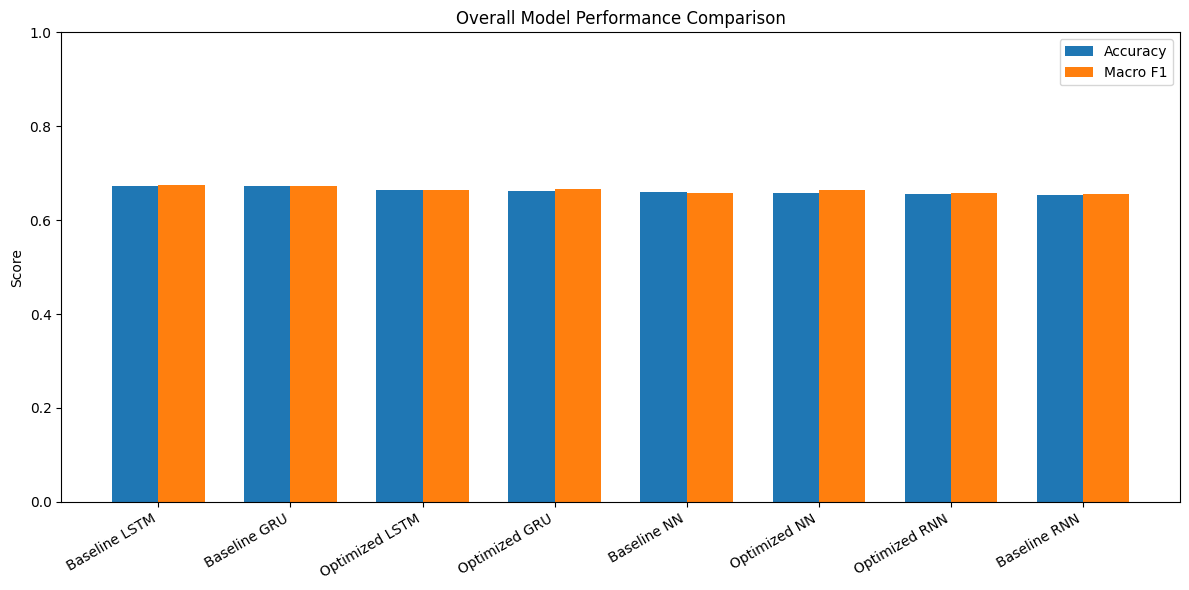

In [76]:
plt.figure(figsize=(12, 6))

x = np.arange(len(overall_results))
width = 0.35

plt.bar(
    x - width/2,
    overall_results["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width/2,
    overall_results["Macro F1"],
    width,
    label="Macro F1"
)

plt.xticks(x, overall_results["Model"], rotation=30, ha="right")
plt.ylabel("Score")
plt.title("Overall Model Performance Comparison")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### 60. Final Evaluation of Best Model on Test Dataset

The baseline LSTM achieved the highest validation accuracy and macro F1-score. It is therefore selected for final evaluation on the untouched test dataset to assess its generalization performance.

In [77]:
# Generate predictions on the untouched test dataset
lstm_test_pred = np.argmax(
    lstm_model.predict(X_test),
    axis=1
)

# Calculate test metrics
test_accuracy = accuracy_score(y_test, lstm_test_pred)
test_precision = precision_score(
    y_test, lstm_test_pred, average="macro", zero_division=0
)
test_recall = recall_score(
    y_test, lstm_test_pred, average="macro", zero_division=0
)
test_f1 = f1_score(
    y_test, lstm_test_pred, average="macro", zero_division=0
)

print("Best Model: Baseline LSTM")
print("\nTest Set Performance")
print("---------------------")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"Macro F1:  {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    lstm_test_pred,
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

163/163 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step
Best Model: Baseline LSTM

Test Set Performance
---------------------
Accuracy:  0.6700
Precision: 0.6874
Recall:    0.6649
Macro F1:  0.6703

Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.55      0.63      1546
     Neutral       0.58      0.69      0.63      1930
    Positive       0.75      0.75      0.75      1730

    accuracy                           0.67      5206
   macro avg       0.69      0.66      0.67      5206
weighted avg       0.68      0.67      0.67      5206



### 61. Confusion Matrix of the Best Model

A confusion matrix is used to visualize the classification performance of the selected baseline LSTM model on the test dataset. It shows the correctly classified and misclassified instances across the three sentiment categories.

163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


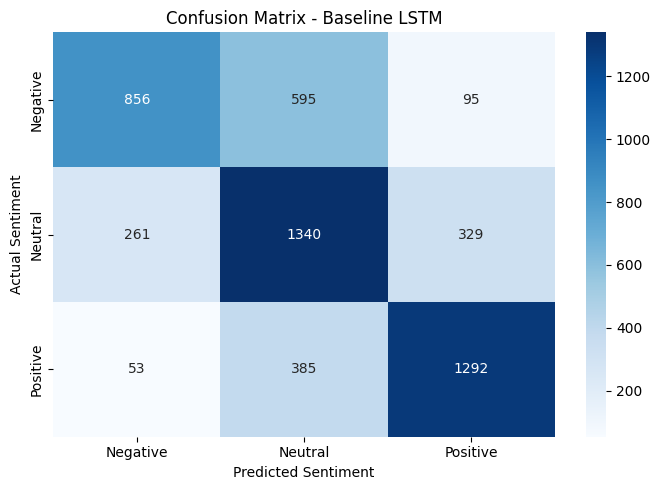

In [78]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Generate test predictions again
lstm_test_pred = np.argmax(
    lstm_model.predict(X_test),
    axis=1
)

# Create confusion matrix
cm = confusion_matrix(y_test, lstm_test_pred)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix - Baseline LSTM")
plt.tight_layout()
plt.show()

### Conclusion

This project implemented and compared four neural network architectures: Neural Network (NN), Simple Recurrent Neural Network (RNN), Long Short-Term Memory (LSTM), and Gated Recurrent Unit (GRU) for multiclass sentiment classification using the Sp1786/multiclass-sentiment-analysis-dataset.

Baseline and hyperparameter-optimized models were developed using TensorFlow/Keras, with KerasTuner employed for automated hyperparameter optimization. The models were evaluated using accuracy, precision, recall, and Macro F1-score.

Based on the validation results, the Baseline LSTM achieved the best overall performance, with an accuracy of 67.36% and a Macro F1-score of 67.53%. The Baseline GRU followed closely, achieving 67.20% accuracy. The Baseline Neural Network achieved the highest precision of 70.27%.

The best-performing model, Baseline LSTM, was further evaluated on the test dataset, achieving 67.00% accuracy, 68.74% precision, 66.49% recall, and 67.03% Macro F1-score.

The comparison showed that hyperparameter tuning did not consistently improve the performance of all architectures. While some optimized models showed improvements in individual metrics, the baseline LSTM and GRU performed better overall than their optimized counterparts.

Overall, the experiments demonstrate that LSTM provided the best classification performance among the four evaluated architectures for this dataset. Further improvements could be explored through advanced text preprocessing, pretrained word embeddings, and transformer-based models.